# 18 — Local Ollama and GeoLibre's native assistant

**Question:** can a browser map use an AI model running on your own desktop?

This lab prepares a tiny, inspectable project for **GeoLibre's actual chat panel**. Its default run makes no inference request. Work through [the setup chapter](../advanced/ollama-assistant.md) first; Ollama's Apps launcher is not the GeoLibre integration screen.

You will identify the runtime boundary, inspect twelve invented polygons, and open the project in the full GeoLibre web app. A downloaded model and explicit browser permissions are necessary for live chat.


## Start here: the question behind the code

**Where does the model run when GeoLibre chats?**

**What you will learn:** inspect → connect → open → verify. The numbered reading guides below follow the actual code cells. Read a guide, predict the output, then run its cell with **Shift+Enter**. Run from top to bottom; changing an upstream value requires rerunning the cells that use it.

**GeoAI connection:** Local-model setup and native GeoLibre practice; no model is trained in this notebook.

**Why this is useful:** A visible runtime boundary helps learners see which component holds the map, runs inference and needs permission.

**Where the work happens:** Pyodide prepares a synthetic project. The full GeoLibre web app can call a separate desktop Ollama service after explicit setup.

![Local AI, browser map. Check twelve invented polygons before asking an assistant about them. Opt into a local-service check after configuring exact origins. Move a reviewed map recipe into the full GeoLibre web app. Check seven selected cells against the native assistant's transcript.](assets/learning/18/infographic.svg)

### Watch the idea unfold

[![Preview: Local AI, browser map — 32-second captioned walkthrough](assets/learning/18/poster.png)](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/files/assets/learning/18/watch.html)

[▶ Watch the captioned mini-video and read its transcript](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/files/assets/learning/18/watch.html) · [Launch this notebook](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/lab/index.html?path=18_ollama_geolibre_setup.ipynb) · [Read this Book chapter](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/notebooks/18_ollama_geolibre_setup.html) · [Python and browser learning guide](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/learning-guide.html)

The video is a silent four-step teaching storyboard with player controls and captions. Open the companion page to play, pause, seek or download it. The local copy is bundled under `assets/learning/18/`; downloaded media can be played offline. The infographic and the text below cover the same ideas without a video player.

**Video transcript:**

1. **Inspect (0–8 s):** Check twelve invented polygons before asking an assistant about them. Code landmark: `len(cells['features'])`.

2. **Connect (8–16 s):** Opt into a local-service check after configuring exact origins. Code landmark: `LIVE_CONNECT = True`.

3. **Open (16–24 s):** Move a reviewed map recipe into the full GeoLibre web app. Code landmark: `native_project.to_project()`.

4. **Verify (24–32 s):** Check seven selected cells against the native assistant's transcript. Code landmark: `heat_proxy_c >= 39`.


### Code guide 1 — Prepare the browser and local-service tools

**Read the Python:** The runtime check installs browser-compatible map and plotting packages only in Pyodide. Imports expose the local helper functions. No network request to Ollama occurs in this setup cell.

**Look for:** Plotting, map-building and optional local-model functions are ready.

**Pause and try:** Which packages render a map, and which helper will contact Ollama only when explicitly called?


In [1]:
import sys, json
from pathlib import Path
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["geolibre==3.0.0", "anywidget"])
    from pyodide import loadPackage
    await loadPackage("matplotlib")
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from IPython.display import display, Markdown, FileLink
from ollama_mapping import (BASE_URL, MODEL, FIXTURE_PLAN, COLORS, diagnose,
    synthetic_cells, validate_plan, preview_plan, apply_plan, demo_map, propose_map)
print("Browser" if sys.platform == "emscripten" else "Ordinary Python", "— no model request made")


Ordinary Python — no model request made


### Code guide 2 — Check the local boundary

**Read the Python:** The Boolean switch prevents an automatic request. `await` lets the browser wait without synchronous requests. The diagnostic returns a status, never a made-up model list.

**Look for:** Default: not probed. Live: server version and installed model names, or a next step.

**Pause and try:** Why can a terminal succeed while the browser reports a network error?


In [2]:
LIVE_CONNECT = False  # Explicit opt-in: contact only this computer's Ollama.
connection = None     # Clear an old result before retrying.
if LIVE_CONNECT:
    connection = await diagnose(base_url=BASE_URL)
    print(json.dumps(connection, indent=2))
else:
    print("Not probed. Set LIVE_CONNECT=True after the chapter's local setup.")
print("Expected model tag:", MODEL, "| Ollama:", BASE_URL)


Not probed. Set LIVE_CONNECT=True after the chapter's local setup.
Expected model tag: qwen3:4b | Ollama: http://127.0.0.1:11434


A successful terminal request is not proof that a web page has permission. An empty `models` list means the server is reachable but no model is installed. A browser failure can have several causes; do not bypass CORS or disable browser protections. Open [GeoLibre Web](https://web.geolibre.app/) in a top-level tab and grant Local Network Access only if you trust that site.


### Code guide 3 — Inspect the source before asking AI

**Read the Python:** Two loops created twelve polygon features with invented values. Matplotlib draws their rings and labels; GeoLibre receives the same FeatureCollection. Longitude comes first.

**Look for:** Twelve labeled cells, with values from 35 to 43. They are not measured temperatures.

**Pause and try:** Count values of 39 or more by hand. You should find seven.


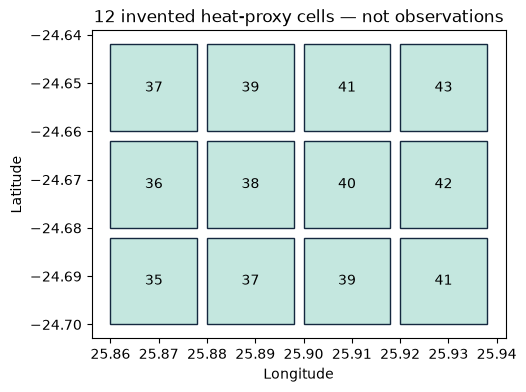

In [3]:
cells = synthetic_cells()
assert len(cells["features"]) == 12
fig, ax = plt.subplots(figsize=(7, 4))
for feature in cells["features"]:
    ring = feature["geometry"]["coordinates"][0]
    ax.add_patch(Polygon(ring, facecolor="#c4e7df", edgecolor="#14283f"))
    ax.text(ring[0][0] + .009, ring[0][1] + .009,
            str(feature["properties"]["heat_proxy_c"]), ha="center", va="center")
ax.autoscale(); ax.set_aspect("equal")
ax.set(xlabel="Longitude", ylabel="Latitude", title="12 invented heat-proxy cells — not observations")
plt.show()
native_project = demo_map()
display(native_project)


### Code guide 4 — Export a map recipe

**Read the Python:** The project dictionary stores the layer and camera. `json.dumps` serializes it; `Path` writes into the notebook's own filesystem. The full GeoLibre link in the next section opens a separate workspace.

**Look for:** A local JSON export and instructions for GeoLibre's native chat panel.

**Pause and try:** Open the full app and compare its layer count with the source, before sending a prompt.


In [4]:
project = native_project.to_project()
project["name"] = "Synthetic heat cells — Ollama learning project"
export_dir = Path("exports"); export_dir.mkdir(exist_ok=True)
project_path = export_dir / "ollama-lesson.geolibre.json"
project_path.write_text(json.dumps(project, indent=2, allow_nan=False), encoding="utf-8")
print("Exported", project_path, "with", len(project["layers"][0]["geojson"]["features"]), "features")
if sys.platform == "emscripten":
    display(FileLink(str(project_path)))


Exported exports\ollama-lesson.geolibre.json with 12 features


## Now use the real GeoLibre chat panel

[Open the bundled project in full GeoLibre](https://web.geolibre.app/?url=https%3A%2F%2Fjltobias.github.io%2FJupyterLite-GeoLibre-GeoAI%2Flite%2Ffiles%2Fdata%2Follama-demo.geolibre.json). This public copy has the same twelve cells. Alternatively download your export and open it using GeoLibre's project controls. Your JupyterLite filesystem is not your Windows filesystem.

1. In **Settings → AI Providers**, select Ollama, base URL `http://127.0.0.1:11434`, model `qwen3:4b` (or your verified installed tool-capable model). No API key is needed.
2. Open **Processing → AI Assistant**. Use typed prompts, with optional hosted routing/search providers disabled.
3. Ask: “List the loaded layer names and feature counts. Do not load new data or run code.” Verify one layer and **12** features.
4. Ask: “Set this layer's fill color to orange and set the map pitch to 45 degrees using the built-in map tools.” Inspect the actual tool transcript and layer style. A tilted flat layer is **not** a terrain model.
5. Optional harder task: “Create a new GeoJSON layer containing features where heat_proxy_c >= 39, keeping the original.” Independently verify **7** selected features. Stop if the model substitutes invented data or a different predicate.
6. Inspect what changed and try Undo. Export a new project only after reviewing its content and credentials. Native code fallback can bypass normal undo; prompt wording is not a hard safety restriction.

No Python cell above has sent a prompt to GeoLibre's assistant. The embedded notebook map and the full web app have separate project state. Continue to [lab 19](19_ollama_chat_to_map.ipynb) for a deliberately bounded notebook-side alternative.


## Sources, privacy and next step

The polygons and Celsius-like `heat_proxy_c` values are **invented teaching data**, not measured heat, clinic locations, disease rates or climate projections. GeoLibre renders the map; Ollama runs optional inference on your computer, not inside Pyodide. Basemaps and the hosted viewer still use the network. Do not enter patient records, credentials or confidential prompts.

Read the [advanced chapter](../advanced/ollama-assistant.md), [GeoLibre AI Assistant guide](https://geolibre.app/user-guide/ai-assistant/), [Ollama chat API](https://docs.ollama.com/api/chat) and [structured-output documentation](https://docs.ollama.com/capabilities/structured-outputs). These are independent teaching examples, not a Horizon integration. [Global Nature Watch Horizon](https://horizon.globalnaturewatch.org/) supplies interaction inspiration, not these data or model results. Sources accessed 11 October 2026.


## Make sense of the result

![Is the model running inside this map? No. The browser calls Ollama on this computer. I will check both the service and browser permission.](assets/learning/18/cartoon.svg)

**Cartoon transcript:** Is the model running inside this map? → No. The browser calls Ollama on this computer. → I will check both the service and browser permission.

**Explain it to a colleague:** Does local inference mean every map request stays offline?

<details><summary>Check your reasoning</summary>

No. Basemaps, remote layers and the hosted viewer still use the network. Optional hosted AI services must also be considered.

</details>

Write three sentences: **I used…** (source and units), **the code computed…** (method), and **I can conclude…** (plus a remaining question). Point to the map, chart or table that supports each claim.

All new teaching illustrations are original schematics. Their marks and fictional dialogue are explanatory, not observations, fitted predictions or captured AI conversations. The existing citation cells identify the analytical data.


## GeoLibre creator and software attribution

GeoLibre is developed by **Qiusheng Wu and contributors**. Recommended citation: Wu, Q. (2026). *GeoLibre: A lightweight, cloud-native GIS platform for visualizing, exploring, and analyzing geospatial data.* Zenodo. [doi:10.5281/zenodo.20785400](https://doi.org/10.5281/zenodo.20785400). See [the official citation guidance](https://geolibre.app/citation/) and [source and MIT license](https://github.com/opengeos/GeoLibre). These browser lessons pin the Python builders to `geolibre==3.0.0`; the independently hosted viewer may change. This repository supplies the JupyterLite adapter and teaching materials, not the upstream GIS. Keep the original dataset, demo-author and basemap credits when sharing a result.
